# Proyecto BloodMNIST — orquestación
Este notebook llama módulos y scripts del proyecto. La lógica de carga, EDA y entrenamiento vive en `src/` y `scripts/`. El split test queda reservado para la evaluación final.

In [2]:
# Importar utilidades de rutas y módulos del proyecto.
from pathlib import Path
import sys

# Encontrar la raíz tanto si Jupyter abrió el repo como notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

# Leer y mostrar los escenarios vigentes en el archivo de configuración.
from bloodmnist.config import load_config
config = load_config(ROOT / 'configs' / 'experiments.json')
[(s['id'], s['description'], s['learning_rate']) for s in config['scenarios']]

[('A1', 'CNN base', 0.001),
 ('A2', 'CNN base + BatchNorm', 0.001),
 ('A3', 'CNN + BatchNorm + Dropout', 0.001),
 ('D1', 'CNN base + Dropout (p=0.3), sin BatchNorm', 0.001),
 ('C1', 'CNN base with lower learning rate', 0.0003)]

### Validación de los escenarios

- **A1:** CNN base, tasa de aprendizaje 0.001.
- **A2:** CNN base + BatchNorm, tasa de aprendizaje 0.001.
- **A3:** CNN + BatchNorm + Dropout (p=0.3), tasa de aprendizaje 0.001.
- **D1:** CNN base + Dropout (p=0.3), sin BatchNorm.
- **C1:** CNN base con tasa de aprendizaje reducida a 0.0003.

## EDA inicial
La siguiente celda usa únicamente train y validation y genera los resúmenes, la distribución de clases y ejemplos representativos de train.

In [3]:
# Ejecutar el EDA modular como subproceso desde la raíz del proyecto.
import subprocess
subprocess.run([sys.executable, str(ROOT / 'scripts' / 'run_eda.py')], cwd=ROOT, check=True)

CompletedProcess(args=['c:\\Users\\User\\Documents\\Clases\\DeepLearning\\Parcial 2 CNN\\Proyecto_CNN_BloodMNIST\\.venv\\Scripts\\python.exe', 'c:\\Users\\User\\Documents\\Clases\\DeepLearning\\Parcial 2 CNN\\Proyecto_CNN_BloodMNIST\\scripts\\run_eda.py'], returncode=0)

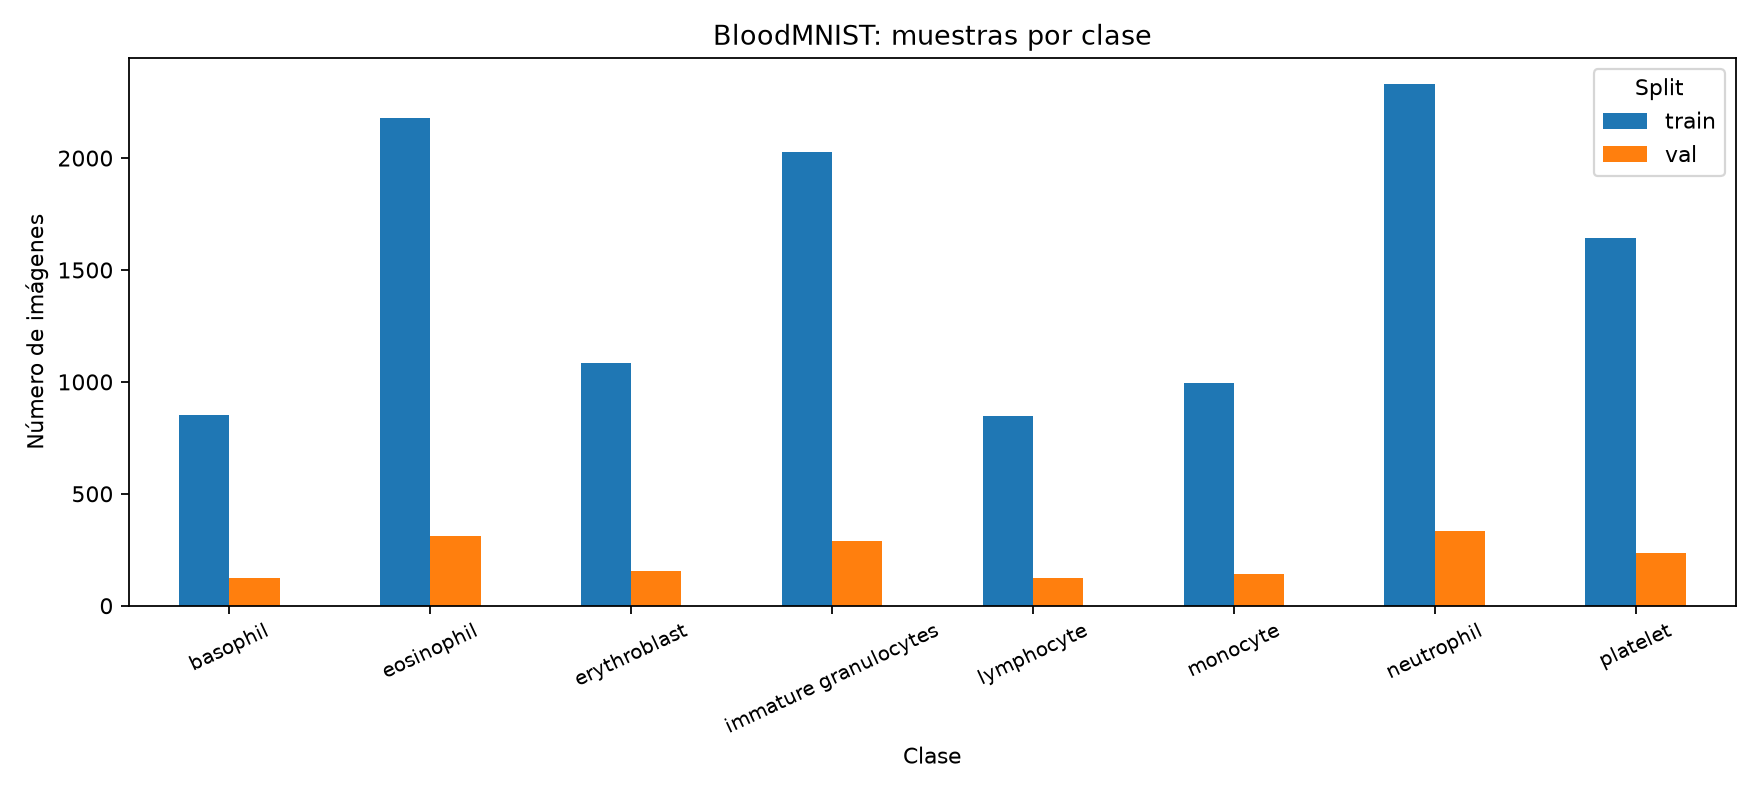

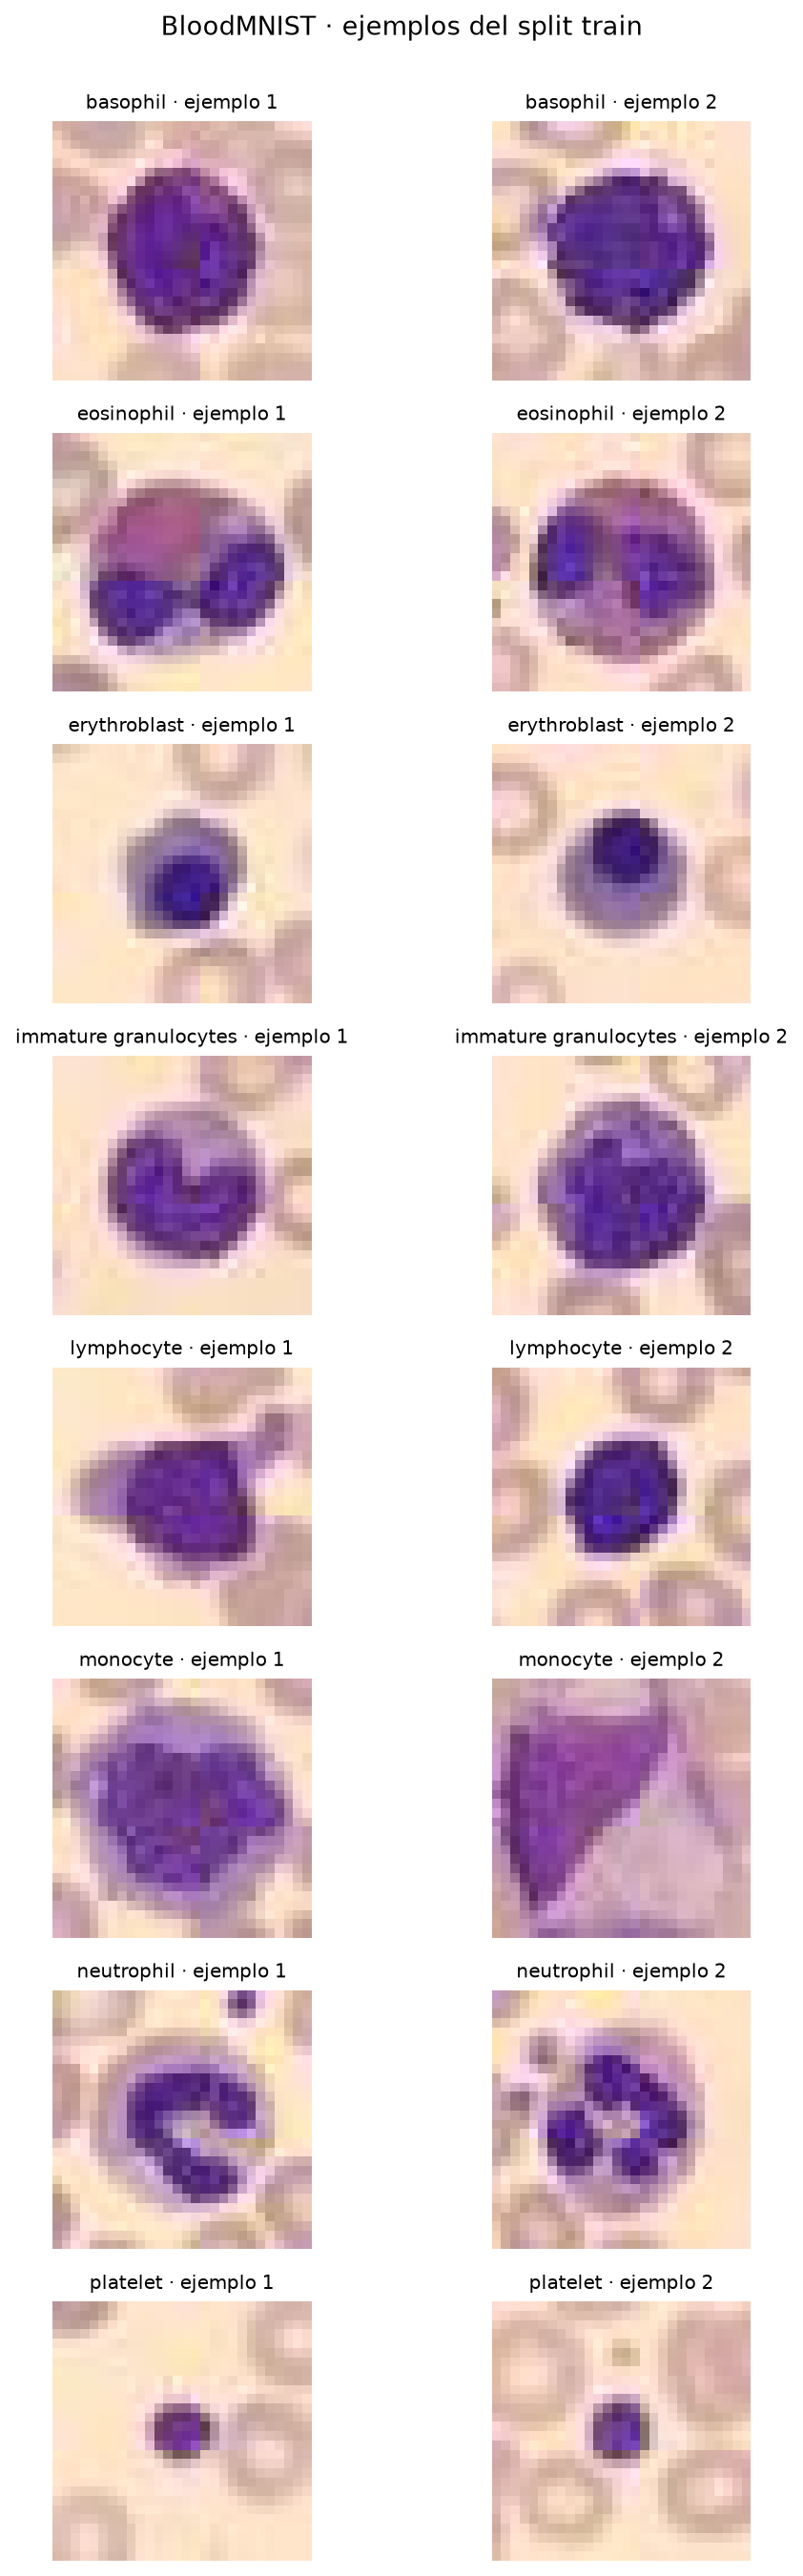

In [4]:
# Mostrar las imágenes generadas por el script, sin duplicar su lógica aquí.
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'outputs' / 'eda' / 'class_distribution.png')))
display(Image(filename=str(ROOT / 'outputs' / 'eda' / 'train_examples.png')))

## Registro de observaciones
Los conteos de train muestran desbalance entre clases: la etiqueta 6 (neutrófilo) tiene 2,330 imágenes, frente a 849 para la etiqueta 4 (linfocito) y 852 para la etiqueta 0 (basófilo). En la cuadrícula, algunas clases muestran formas compactas y núcleos oscuros parecidos a 28×28 píxeles, mientras que neutrófilos y eosinófilos exhiben núcleos lobulados en estos ejemplos. Son observaciones de una muestra pequeña, no evidencia de confusión del modelo. Pregunta inicial: ¿BatchNorm + Dropout reduce la brecha entre train y validation sin perjudicar el macro-F1 y el recall de las clases menos representadas? Hipótesis provisional: A3 reducirá esa brecha respecto a A2 y conservará o mejorará el macro-F1 y el recall de basófilos y linfocitos. Revisar la hipótesis con la línea base y las métricas por clase. No consultar el test durante esta exploración.

## Entrenamiento de los escenarios
El plan activo incluye A1, A2, A3, C1 y D1. B1 (early stopping) completó las 40 épocas y se conserva solo como antecedente histórico.

In [ ]:
# Este bloque queda desactivado para que abrir el notebook no repita las corridas.
# Las figuras e historiales existentes se leen en las secciones siguientes.
# Para regenerar todos los resultados desde cero, descomenta y ejecuta la línea:
# subprocess.run([sys.executable, str(ROOT / 'scripts' / 'run_training.py'), '--all'], cwd=ROOT, check=True)
# Atención: la corrida sobrescribe historiales y checkpoints de los cinco escenarios activos.

CompletedProcess(args=['c:\\Users\\User\\Documents\\Clases\\DeepLearning\\Parcial 2 CNN\\Proyecto_CNN_BloodMNIST\\.venv\\Scripts\\python.exe', 'c:\\Users\\User\\Documents\\Clases\\DeepLearning\\Parcial 2 CNN\\Proyecto_CNN_BloodMNIST\\scripts\\run_training.py', '--scenario', 'D1'], returncode=0)

## Revisión y evaluación final
El informe compara validation para los escenarios activos. B1 queda fuera de esa tabla, pero sus archivos se conservan como antecedente histórico.

## Informe de resultados

Esta sección lee los resultados guardados de los cinco escenarios activos y presenta sus curvas, métricas de validación y la evaluación final registrada. No vuelve a entrenar. La celda de evaluación consulta test solo si aún no existe `outputs/final_evaluation/test_metrics.json`; si el archivo está presente, reutiliza las métricas. La selección del checkpoint se basa en validation; test no se usa para comparar escenarios.

In [7]:
# Cargar resultados existentes y preparar las rutas que usan las secciones siguientes.
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

# Leer la comparación y separar escenarios activos de antecedentes retirados.
RUNS = ROOT / "outputs" / "runs"
all_comparison = json.loads((RUNS / "comparison.json").read_text(encoding="utf-8"))
active_ids = [item["id"] for item in config["scenarios"]]
comparison = [run for run in all_comparison if run["scenario"]["id"] in active_ids]
retired_scenarios = [run for run in all_comparison if run["scenario"]["id"] not in active_ids]

# Leer las métricas A3 ya guardadas; esto no vuelve a ejecutar el modelo sobre test.
completed_ids = {run["scenario"]["id"] for run in comparison}
missing_ids = [scenario_id for scenario_id in active_ids if scenario_id not in completed_ids]
print("Escenarios activos con resultados:", ", ".join(run["scenario"]["id"] for run in comparison))
if missing_ids:
    print("Pendientes de ejecutar:", ", ".join(missing_ids))
if retired_scenarios:
    print("Históricos excluidos:", ", ".join(run["scenario"]["id"] for run in retired_scenarios))


Escenarios activos con resultados: A1, A2, A3, D1, C1
Históricos excluidos: B1
El test ya está evaluado una vez con A3; aquí solo se leen sus métricas.


## Curvas individuales por escenario

Cada figura se muestra desde `outputs/runs/<ID>/training_curves.png`. Así puedes revisar primero las curvas de entrenamiento y validación de cada escenario.

### A1 — CNN base

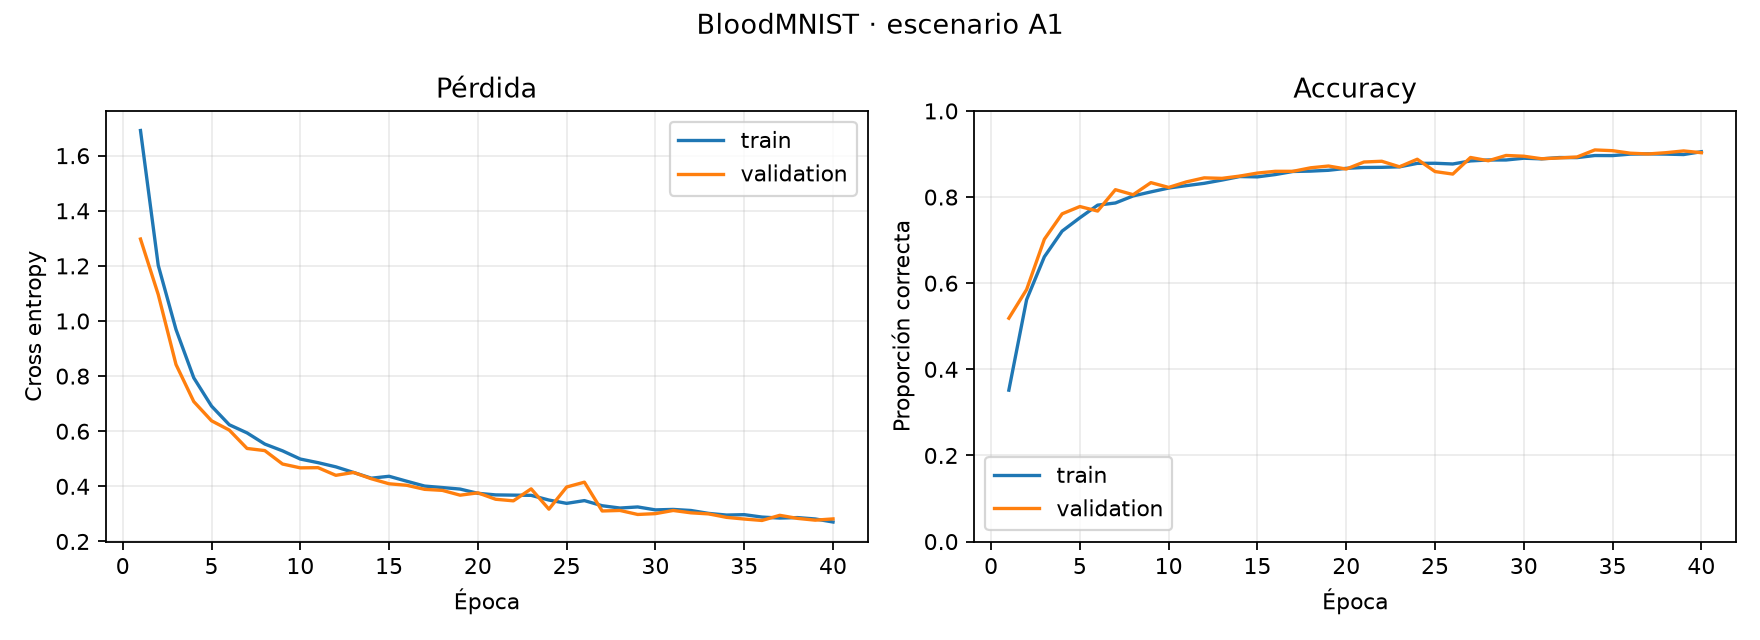

### A2 — CNN base + BatchNorm

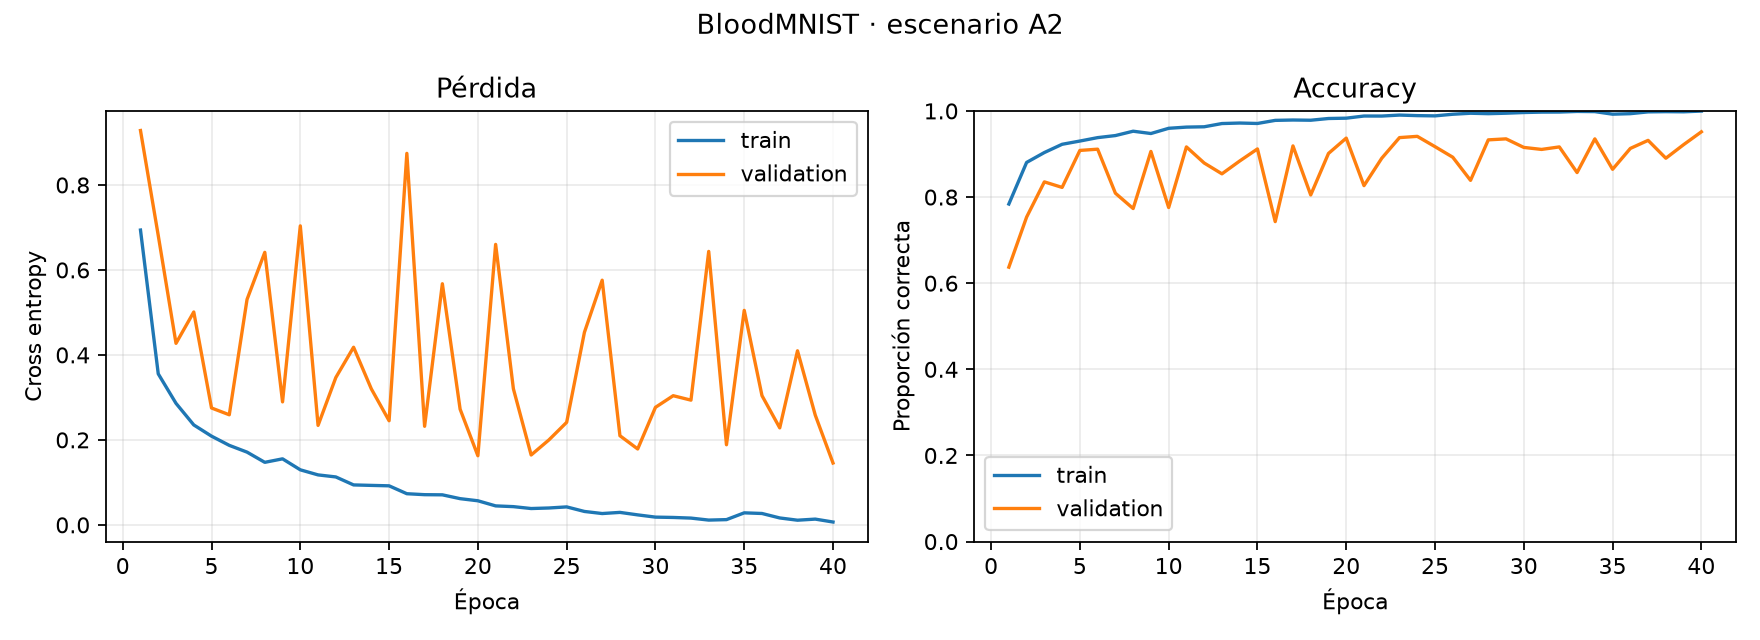

### A3 — CNN + BatchNorm + Dropout

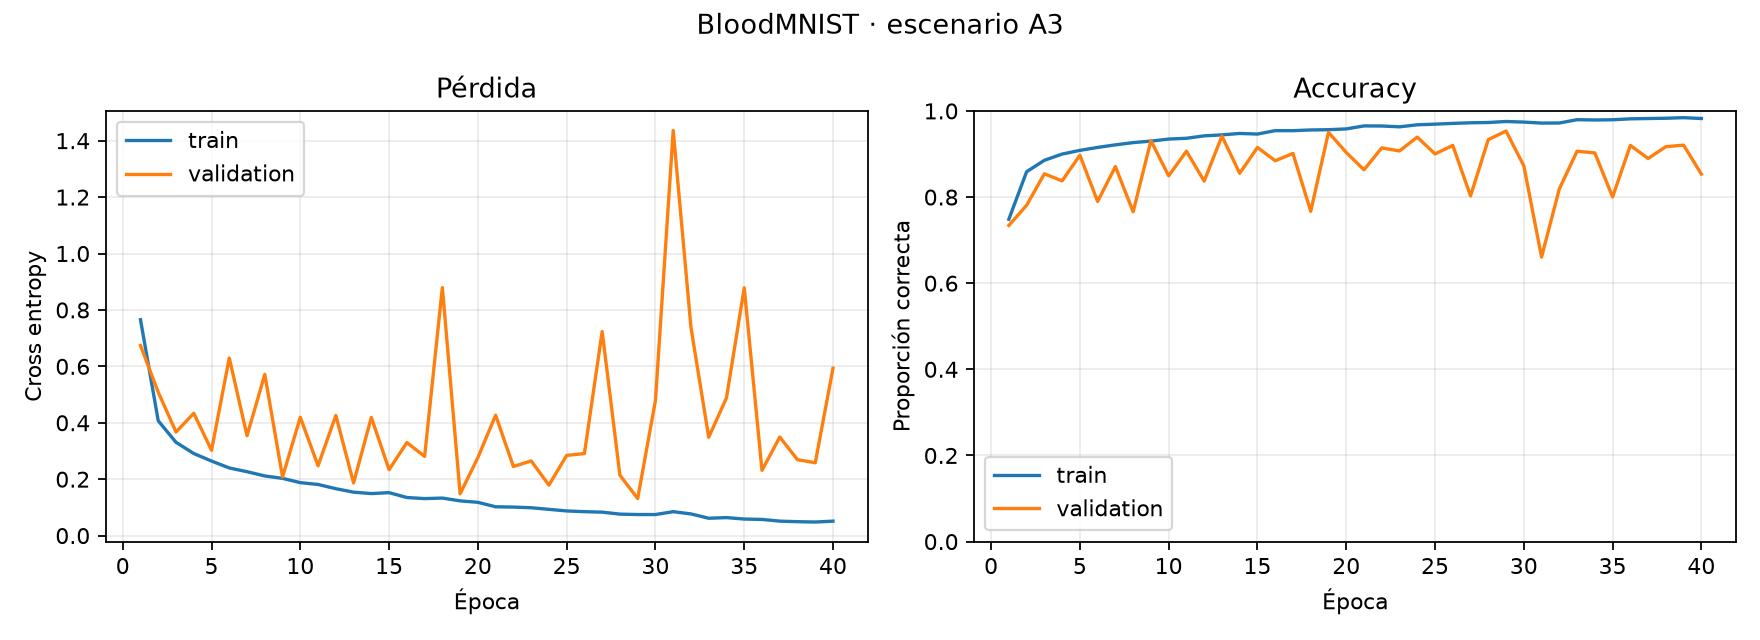

### D1 — CNN base + Dropout (p=0.3), sin BatchNorm

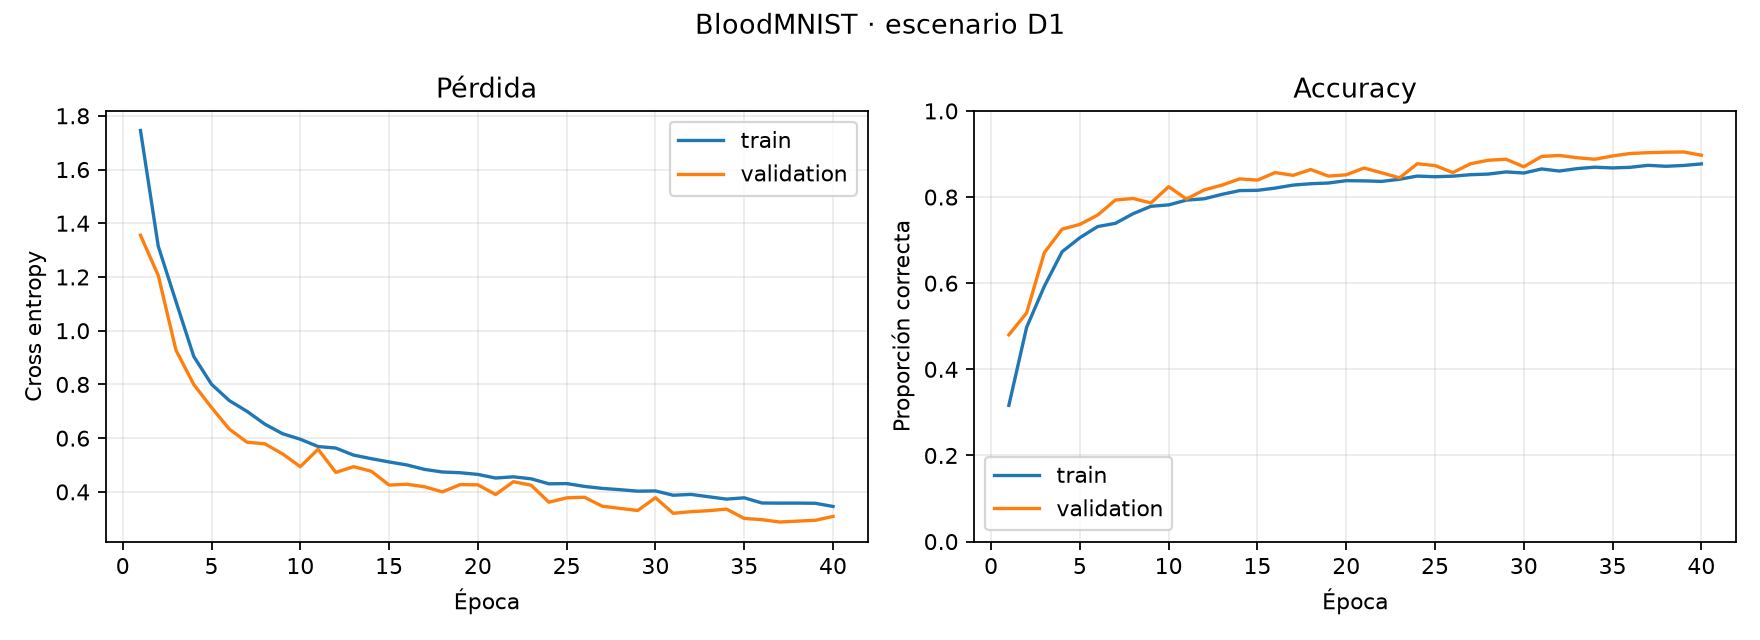

### C1 — CNN base with lower learning rate

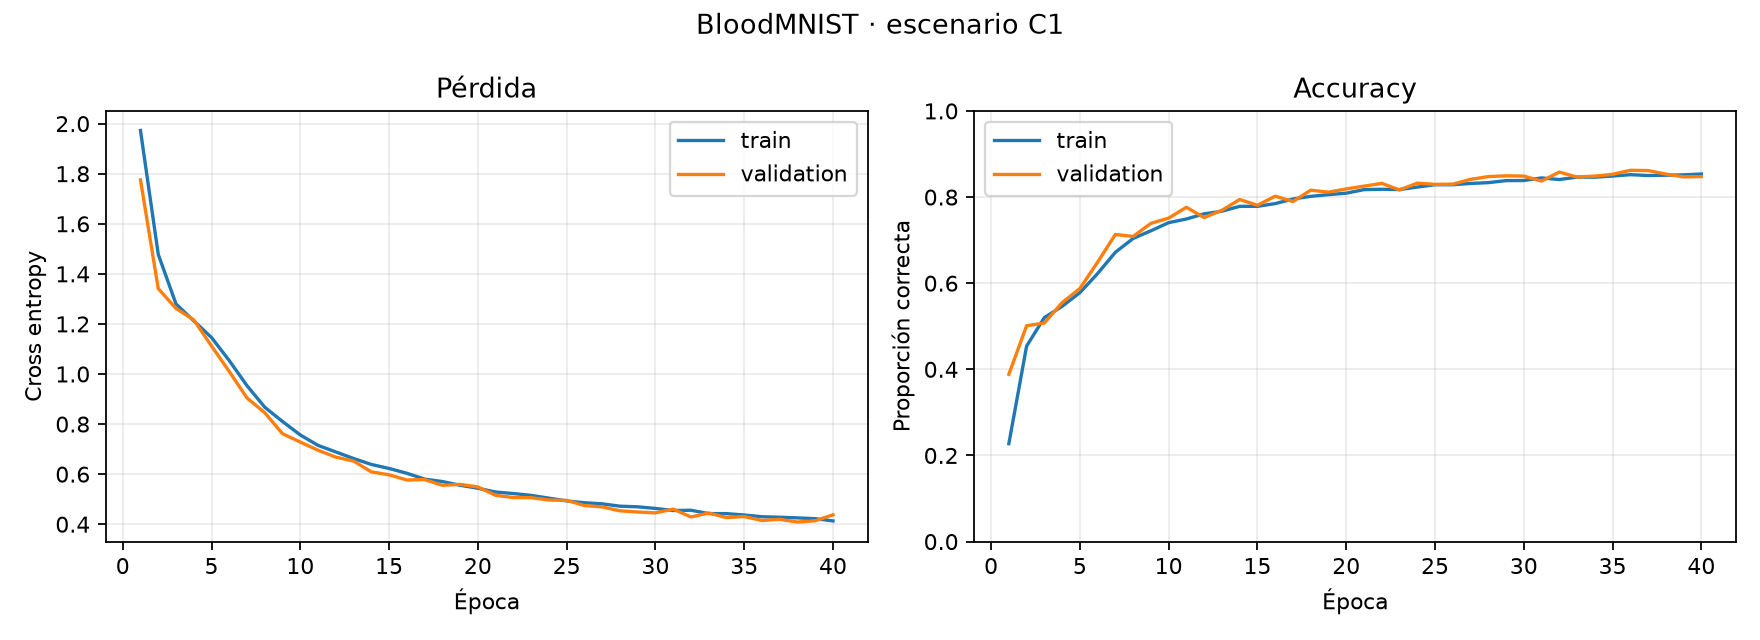

In [8]:
# Mostrar la figura guardada de cada escenario antes de las gráficas conjuntas.
for run in comparison:
    scenario_id = run["scenario"]["id"]
    description = run["scenario"]["description"]
    curve_path = RUNS / scenario_id / "training_curves.png"

    # Crear un subtítulo para separar visualmente las salidas individuales.
    display(Markdown(f"### {scenario_id} — {description}"))
    if curve_path.is_file():
        display(Image(filename=str(curve_path)))
    else:
        print(f"No se encontró la curva de {scenario_id}: {curve_path}")


## Comparación conjunta de validación

La tabla ordena escenarios activos por macro-F1. Los dos paneles comparan sus historiales guardados de pérdida y macro-F1 de validación.

,Escenario,Configuración,Épocas,Mejor época,Pérdida val.,Exactitud val.,Macro-F1 val.,Macro-recall val.
0,A3,CNN + BatchNorm + Dropout,40,29,0.1315,95.33%,94.82%,95.05%
1,A2,CNN base + BatchNorm,40,40,0.1456,95.15%,94.66%,95.03%
2,D1,"CNN base + Dropout (p=0.3), sin BatchNorm",40,37,0.2878,90.30%,88.83%,88.21%
3,A1,CNN base,40,36,0.2762,90.19%,88.72%,88.48%
4,C1,CNN base with lower learning rate,40,38,0.4088,85.34%,81.93%,80.93%


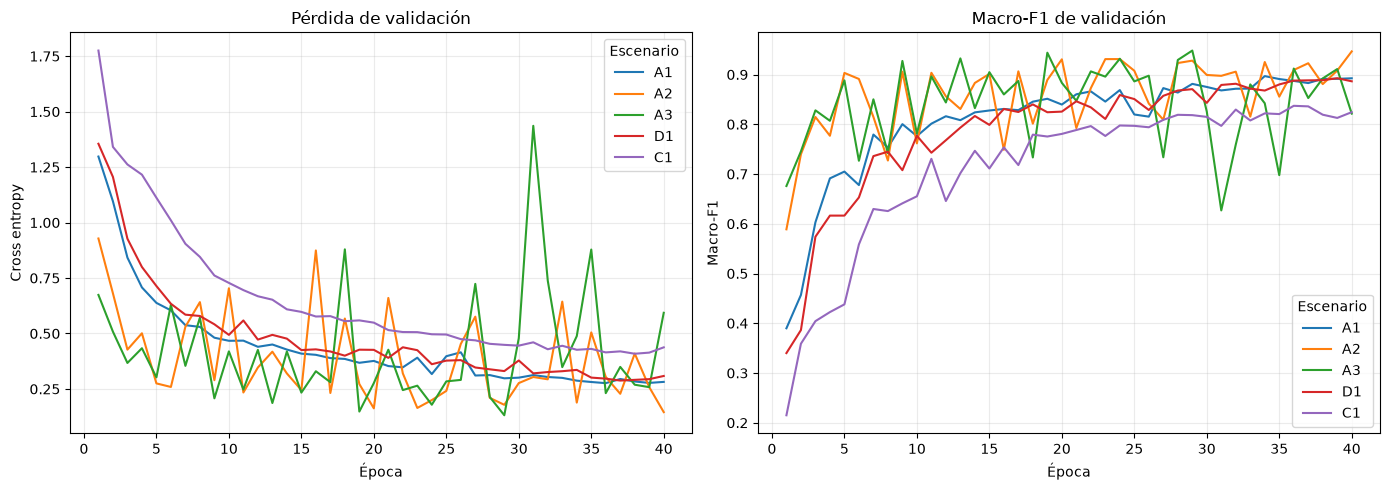

Mayor macro-F1 de validación: A3 (94.82%).


In [9]:
# Extraer métricas del mejor checkpoint de validación para cada escenario activo.
rows = []
for run in comparison:
    val = run["validation_at_best_checkpoint"]
    rows.append({
        "Escenario": run["scenario"]["id"],
        "Configuración": run["scenario"]["description"],
        "Épocas": run["epochs_completed"],
        "Mejor época": run["best_epoch"],
        "Pérdida val.": val["loss"],
        "Exactitud val.": val["accuracy"],
        "Macro-F1 val.": val["macro_f1"],
        "Macro-recall val.": val["macro_recall"],
    })

# Ordenar por macro-F1 para dar el mismo peso a cada clase.
results_table = pd.DataFrame(rows).sort_values("Macro-F1 val.", ascending=False).reset_index(drop=True)
display(results_table.style.format({
    "Pérdida val.": "{:.4f}", "Exactitud val.": "{:.2%}",
    "Macro-F1 val.": "{:.2%}", "Macro-recall val.": "{:.2%}",
}))

# Leer los archivos de historial producidos por cada entrenamiento.
histories = {
    run["scenario"]["id"]: json.loads((RUNS / run["scenario"]["id"] / "history.json").read_text(encoding="utf-8"))
    for run in comparison
}

# Comparar pérdida y macro-F1 de validation en paneles separados.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for scenario_id, history in histories.items():
    epochs = [point["epoch"] for point in history]
    axes[0].plot(epochs, [point["validation"]["loss"] for point in history], label=scenario_id)
    axes[1].plot(epochs, [point["validation"]["macro_f1"] for point in history], label=scenario_id)
axes[0].set(title="Pérdida de validación", xlabel="Época", ylabel="Cross entropy")
axes[1].set(title="Macro-F1 de validación", xlabel="Época", ylabel="Macro-F1")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(title="Escenario")
fig.tight_layout()
plt.show()

# Resumir el líder usando validation; test no participa en esta elección.
if not results_table.empty:
    best_f1 = results_table.iloc[0]
    print(f"Mayor macro-F1 de validación: {best_f1['Escenario']} ({best_f1['Macro-F1 val.']:.2%}).")


## Evaluación final en test (una sola vez)

El resultado registrado corresponde al checkpoint A3 seleccionado con validation. Si `outputs/final_evaluation/test_metrics.json` existe, el bloque solo carga ese archivo. Si falta, ejecuta la evaluación final con A3 —si el checkpoint está disponible— y guarda las métricas para las celdas siguientes. No borres el archivo para repetir la evaluación: test se reserva para una sola evaluación final.

In [ ]:
# Definir el archivo final y el checkpoint seleccionado previamente con validation.
final_metrics_path = ROOT / "outputs" / "final_evaluation" / "test_metrics.json"
selected_scenario_id = "A3"
selected_checkpoint = RUNS / selected_scenario_id / f"{selected_scenario_id}_best.pt"

# Reutilizar el resultado existente para no volver a consultar el split test.
if final_metrics_path.is_file():
    test_result = json.loads(final_metrics_path.read_text(encoding="utf-8"))
    print(f"Evaluación ya registrada para {test_result['scenario_id']}; se reutilizan sus métricas.")
else:
    # Si aún no hay resultado, exigir que primero exista el checkpoint elegido.
    if not selected_checkpoint.is_file():
        raise FileNotFoundError(
            f"No existe {selected_checkpoint}. Entrena el escenario y selecciona el checkpoint con validation primero."
        )

    # Ejecutar el evaluador modular, que valida que no exista una evaluación anterior.
    subprocess.run(
        [sys.executable, str(ROOT / "scripts" / "evaluate_final.py"), "--checkpoint", str(selected_checkpoint)],
        cwd=ROOT,
        check=True,
    )
    test_result = json.loads(final_metrics_path.read_text(encoding="utf-8"))


In [10]:
# Mostrar las métricas globales de la evaluación final guardada.
metrics = test_result["metrics"]
print(
    f"Escenario: {test_result['scenario_id']} | muestras: {test_result['test_samples']:,} | "
    f"exactitud: {metrics['accuracy']:.2%} | macro-F1: {metrics['macro_f1']:.2%} | "
    f"macro-recall: {metrics['macro_recall']:.2%} | pérdida: {metrics['loss']:.4f}"
)

# Preparar una fila por clase con soporte y métricas finales.
class_rows = [
    {"Clase": name, "Precisión": values["precision"], "Recall": values["recall"],
     "F1": values["f1"], "Soporte": values["support"]}
    for name, values in metrics["per_class"].items()
]
class_table = pd.DataFrame(class_rows)
display(class_table.style.format({"Precisión": "{:.2%}", "Recall": "{:.2%}", "F1": "{:.2%}"}))


Escenario: A3 | muestras: 3,421 | exactitud: 95.15% | macro-F1: 94.45% | macro-recall: 94.50% | pérdida: 0.1502


,Clase,Precisión,Recall,F1,Soporte
0,basophil,89.11%,90.57%,89.84%,244
1,eosinophil,98.88%,98.88%,98.88%,624
2,erythroblast,96.76%,96.14%,96.45%,311
3,"immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",90.94%,88.43%,89.67%,579
4,lymphocyte,96.58%,93.00%,94.76%,243
5,monocyte,86.62%,91.20%,88.85%,284
6,neutrophil,96.73%,97.75%,97.24%,666
7,platelet,99.79%,100.00%,99.89%,470


### Matriz de confusión final

Las filas son las clases reales y las columnas las predicciones. Se usan los conteos guardados para A3.

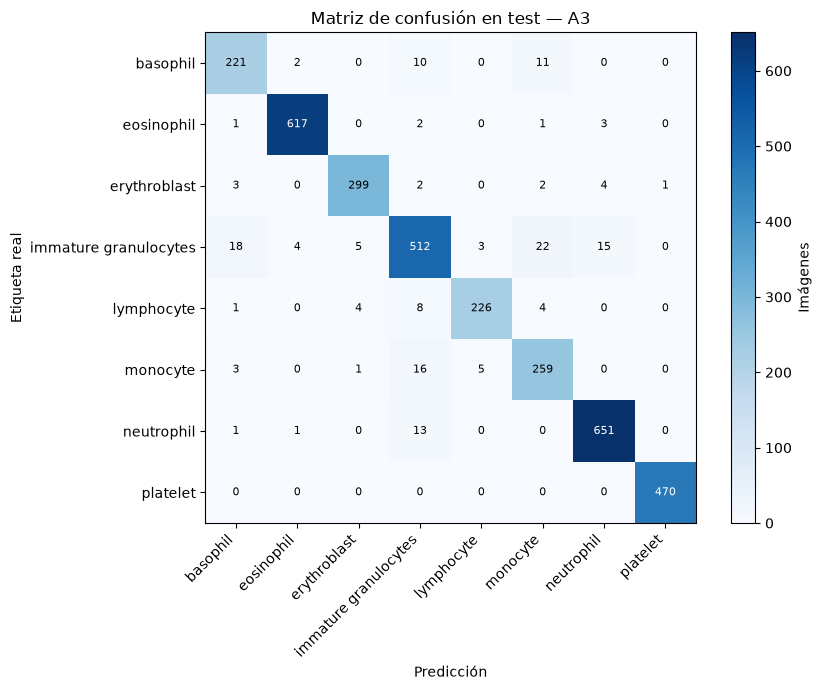

In [11]:
# Recuperar la matriz existente y respetar el orden original de las clases.
class_names = list(metrics["per_class"].keys())
confusion = np.asarray(metrics["confusion_matrix"])

# Dibujar los conteos con etiquetas y barra de color.
fig, axis = plt.subplots(figsize=(9, 7))
image = axis.imshow(confusion, cmap="Blues")
axis.set(title=f"Matriz de confusión en test — {test_result['scenario_id']}",
         xlabel="Predicción", ylabel="Etiqueta real",
         xticks=range(len(class_names)), yticks=range(len(class_names)))
short_names = [name.replace(
    "immature granulocytes(myelocytes, metamyelocytes and promyelocytes)",
    "immature granulocytes") for name in class_names]
axis.set_xticklabels(short_names, rotation=45, ha="right")
axis.set_yticklabels(short_names)

# Anotar cada celda para que los errores entre clases sean fáciles de ubicar.
threshold = confusion.max() / 2
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        color = "white" if confusion[row, column] > threshold else "black"
        axis.text(column, row, str(confusion[row, column]), ha="center", va="center", color=color, fontsize=8)
fig.colorbar(image, ax=axis, label="Imágenes")
fig.tight_layout()
plt.show()


## Análisis de los resultados

La tabla resume el checkpoint de menor pérdida de validación de cada escenario activo. la brecha de exactitud se calcula como **exactitud de entrenamiento menos exactitud de validación**; describe la diferencia observada en ese checkpoint y no demuestra por sí sola sobreajuste.

| Escenario | Mejor época | Pérdida val. | Exactitud val. | Macro-F1 val. | Macro-recall val. | Gap |
|---|---:|---:|---:|---:|---:|---:|
| A1 — CNN base | 36 | 0.2762 | 90.19% | 88.72% | 88.48% | −0.03 pp |
| A2 — + BatchNorm | 40 | 0.1456 | 95.15% | 94.66% | 95.03% | 4.81 pp |
| A3 — + BatchNorm y Dropout | 29 | **0.1315** | **95.33%** | **94.82%** | **95.05%** | 3.55 pp |
| D1 — + Dropout, sin BatchNorm | 37 | 0.2878 | 90.30% | 88.83% | 88.21% | −0.64 pp |
| C1 — tasa de aprendizaje 0.0003 | 38 | 0.4088 | 85.34% | 81.93% | 80.93% | −0.07 pp |

A2 y A3 alcanzaron las métricas de validación más altas. Frente a A1, A2 elevó el macro-F1 de 88.72% a 94.66%, mientras que A3 llegó a 94.82%. La diferencia entre A3 y A2 fue pequeña: 0.17 puntos porcentuales de macro-F1 y 0.18 puntos de exactitud. En estas runs, la comparación A1–A2 es consistente con una mejora asociada a BatchNorm; añadir Dropout en A3 coincidió con una mejora adicional leve y con una brecha de exactitud menor que la de A2 (3.55 frente a 4.81 puntos porcentuales). Estos resultados apoyan la hipótesis de forma parcial y descriptiva, no establecen que el efecto se mantenga con otras semillas o configuraciones.

D1, que añade Dropout sin BatchNorm, quedó muy cerca de la CNN base: su macro-F1 de validación fue 88.83% frente a 88.72% en A1. Por tanto, en esta ejecución Dropout por sí solo no produjo una mejora apreciable. C1 obtuvo el resultado más bajo (macro-F1 de 81.93%) tras el límite de 40 épocas; esto muestra que la tasa menor no alcanzó el desempeño de A1 dentro del presupuesto usado, pero no permite concluir qué ocurriría con más épocas o con otra programación del aprendizaje.

La pérdida y las métricas deben leerse en conjunto. A2 tuvo exactitud de entrenamiento de 99.97% frente a 95.15% en validación, mientras que A3 registró 98.88% y 95.33%, respectivamente. La brecha menor de A3 es compatible con una generalización algo más equilibrada que A2 en estos runs; la diferencia pequeña en validación aconseja evitar afirmaciones fuertes sobre la superioridad de una configuración.

## Análisis de errores y evaluación final

El test oficial se usó una sola vez para el escenario A3, seleccionado a partir de validation. En sus 3,421 imágenes, A3 obtuvo **95.15% de exactitud**, **94.45% de macro-F1**, **94.50% de macro-recall** y pérdida de 0.1502. El macro-F1 de test (94.45%) fue cercano al de validación (94.82%), una diferencia descriptiva de 0.37 puntos porcentuales. Como no se evaluaron los demás escenarios en test, esta cifra no sirve para compararlos.

Las métricas por clase muestran un desempeño desigual: el recall más bajo fue el de los granulocitos inmaduros (88.43%), seguido por basófilos (90.57%) y monocitos (91.20%). Plaquetas alcanzó 100% de recall; eosinófilos, 98.88%; eritroblastos, 96.14%; neutrófilos, 97.75%; y linfocitos, 93.00%. La matriz de confusión muestra errores entre granulocitos inmaduros y monocitos (22 casos), granulocitos inmaduros y basófilos (18 casos), y monocitos y granulocitos inmaduros (16 casos). Esto señala qué pares conviene revisar visualmente si se desea profundizar el análisis de errores.

El desbalance observado en train es un contexto relevante, pero estas métricas no permiten atribuir los errores únicamente al tamaño de las clases. Para proponer esa relación habría que estudiar ejemplos mal clasificados y otras posibles similitudes morfológicas; aquí los conteos de confusión se reportan como evidencia descriptiva.

## Conclusiones

- **Respuesta a la pregunta:** entre las configuraciones comparadas, A2 y A3 presentaron el mejor desempeño de validación. BatchNorm coincidió con una mejora amplia frente a la CNN base en esta ejecución. A3 obtuvo el valor más alto, aunque su ventaja sobre A2 fue marginal.
- **Hipótesis sobre BatchNorm y Dropout:** la evidencia respalda parcialmente la expectativa para A3. A3 superó levemente a A2 en validación y mostró una brecha de exactitud menor; sin embargo, la diferencia no basta para afirmar una mejora consistente.
- **Dropout sin BatchNorm:** D1 fue prácticamente equivalente a A1 en macro-F1 de validación. En este diseño no se observó un beneficio relevante de Dropout por sí solo.
- **Tasa de aprendizaje menor:** C1 no alcanzó el desempeño de A1 dentro de 40 épocas. El resultado describe el presupuesto probado y no descarta que una ejecución más larga o un ajuste adicional cambiara el comportamiento.
- **Evaluación final:** A3 mantuvo en test métricas cercanas a las de validación y mostró los recall más bajos en granulocitos inmaduros, basófilos y monocitos. Los errores entre esas clases orientan un análisis visual posterior.

Las conclusiones se limitan a una run por escenario, con semilla 42, CPU y hasta 40 épocas. No se estimó variabilidad entre semillas, y el test se evaluó únicamente con A3. Por ello, los hallazgos permiten describir estas ejecuciones y responder la pregunta dentro del alcance del proyecto, pero no demostrar superioridad universal de una configuración.

**Síntesis:** para estos runs, BatchNorm fue el cambio que coincidió con la mejora más clara respecto de la CNN base; combinarlo con Dropout produjo el mejor resultado observado, con una ventaja pequeña frente a BatchNorm solo. El análisis de test confirma un buen desempeño global de A3 y deja visibles confusiones entre algunas clases celulares.